In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'core').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.figsize': (7, 4)})
FIG = ROOT / 'results' / 'figures'; DATA = ROOT / 'results' / 'data'

# 03 — Part B: two items with complementarities

**Model.** Agent with private type $(v,1-v)$ gets utility
$u_v(z_1,z_2)=v z_1+(1-v)z_2+\varepsilon z_1 z_2$ from bundle $(z_1,z_2)$; $\varepsilon\ge0$ is
common knowledge. (Motivation in the proposal: production vs distribution capacity.)

**Questions.** Does LIP survive complementarities? What is the best strategy-proof mechanism,
and how far is LIP from it? Formal statements and proofs are in `docs/theory/02_eps_model.md`;
this notebook shows the numbers.

| Fact | Where |
|---|---|
| First best $=1+\max\{\varepsilon,\lvert x-y\rvert\}$ | P1 |
| Fixed-menu dictatorships are strategy-proof for every $\varepsilon$ ("$\varepsilon$-aware LIP") | P2 |
| Dictator's problem strictly concave, choice monotone in type $\Rightarrow$ certified brackets | P3–P4 |
| Strategic play against the *naive* additive rule = $\varepsilon$-aware LIP | P5 |
| Comonotone ("nested") lotteries dominate deterministic bundles | P6 |
| LP upper bound over all randomised SP mechanisms (McCormick moments) | P7 |

## 1. The first best and the two trivial mechanisms

With complementarity the efficient allocation is either the additive split (welfare
$1+|x-y|$) or *everything to one agent* (welfare $1+\varepsilon$). Two strategy-proof
mechanisms need no reports at all:

* **take-all**: a fair coin, the winner gets both items — welfare $1+\varepsilon$ always, so
  it is **first best whenever $\varepsilon\ge1$** and $(1+\varepsilon)/2$-competitive below;
* **equal split**: welfare $1+\varepsilon/2$.

So the interesting regime is $\varepsilon\in[0,1)$.

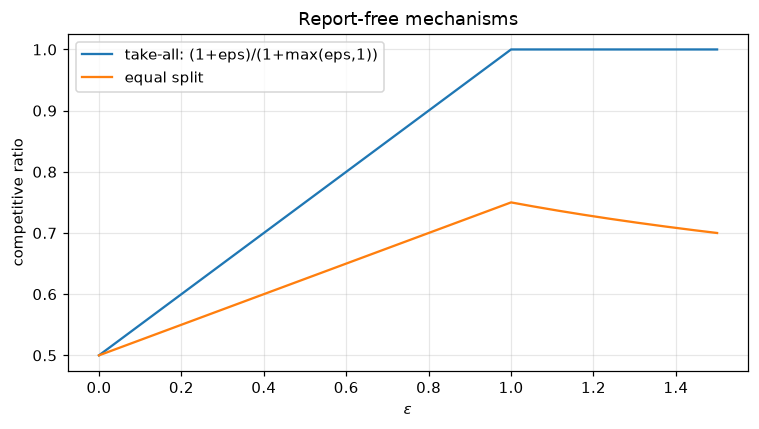

In [2]:
from core import eps as E, lip, lp
e_grid = np.linspace(0, 1.5, 301)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(e_grid, (1 + e_grid) / (1 + np.maximum(e_grid, 1)), label="take-all: (1+eps)/(1+max(eps,1))")
ax.plot(e_grid, (1 + e_grid / 2) / (1 + np.maximum(e_grid, 1)), label="equal split")
ax.set(xlabel=r"$\varepsilon$", ylabel="competitive ratio", title="Report-free mechanisms"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "03_trivial.png"); plt.show()

## 2. $\varepsilon$-aware LIP(a): what the dictator buys

The menu (budget set) is unchanged; the dictator now maximises
$F_v(t)=vQ(t)+(1-v)Q(1-t)+\varepsilon Q(t)Q(1-t)$ over the currency $t$ spent on item 1.
$F_v$ is strictly concave and has increasing differences in $(t,v)$, so the optimal spend is
unique and non-decreasing in $v$. Complementarity shrinks the "all-in" regimes: for
$\varepsilon\ge b/(a+b)\approx0.135$ (at $a=2$) every type buys some of both items.

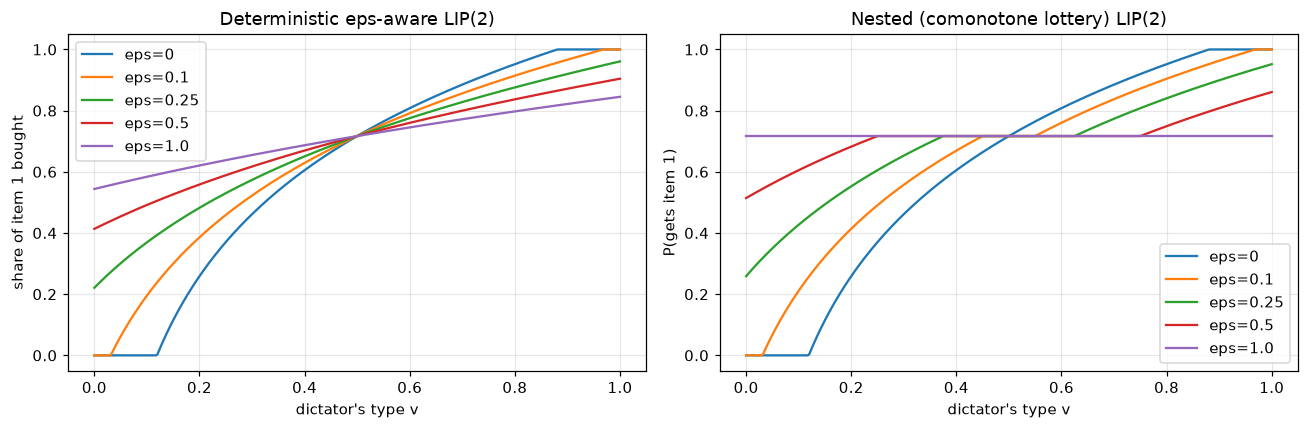

In [3]:
v = np.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for e in (0, 0.1, 0.25, 0.5, 1.0):
    q1, q2 = E.bundle_eps(v, 2.0, e)
    ax[0].plot(v, q1, label=f"eps={e}")
ax[0].set(xlabel="dictator's type v", ylabel="share of item 1 bought", title="Deterministic eps-aware LIP(2)"); ax[0].legend()
for e in (0, 0.1, 0.25, 0.5, 1.0):
    q1, q2 = E.bundle_eps(v, 2.0, e, nested=True)
    ax[1].plot(v, q1, label=f"eps={e}")
ax[1].set(xlabel="dictator's type v", ylabel="P(gets item 1)", title="Nested (comonotone lottery) LIP(2)"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "03_dictator_choice.png"); plt.show()

Right panel: with nested lotteries the dictator is offered the same marginals as lotteries
that are *comonotone* (one uniform draw decides both items), which gives her $\varepsilon\min(m_1,m_2)$
instead of $\varepsilon m_1m_2$. For large $\varepsilon$ every type picks the balanced lottery
— i.e. "I get everything with probability $Q(1/2)\approx0.72$, otherwise you do" — which is
first best.

## 3. Competitive ratios of LIP(2) as $\varepsilon$ grows — and the chatbot draft

The commented-out draft in `proposal/main.tex` tabulated the worst sampled welfare ratio of
"LIP under dominant best responses" against the naive rule. By P5 that is exactly the
$\varepsilon$-aware mechanism, and our certified brackets reproduce the table:

In [4]:
rows = []
for e, draft in ((0.0, 0.82815), (0.01, 0.83082), (0.1, 0.84028), (0.5, 0.81002), (1.0, 0.76515), (2.0, 0.71528)):
    lo, up, arg, _ = E.bracket_lip(2.0, e, tol=1e-4, max_cells=300_000)
    lon, upn, argn, _ = E.bracket_lip(2.0, e, tol=1e-4, max_cells=300_000, nested=True)
    rows.append({"eps": e, "draft 'strategic LIP'": draft, "eps-aware LIP(2) lower": lo, "upper": up, "worst (x,y)": tuple(np.round(arg, 3)),
                 "nested LIP(2) lower": lon, "upper ": upn, "worst (x,y) ": tuple(np.round(argn, 3))})
pd.DataFrame(rows).round(5)

,eps,draft 'strategic LIP',eps-aware LIP(2) lower,upper,"worst (x,y)",nested LIP(2) lower,upper,"worst (x,y)"
0,0.00,0.82815,0.82805,0.82815,"(0.407, 0.0)",0.82805,0.82815,"(0.407, 0.0)"
1,0.01,0.83082,0.83072,0.83082,"(0.412, 0.0)",0.83273,0.83283,"(0.404, 0.0)"
2,0.10,0.84028,0.84018,0.84028,"(0.746, 0.254)",0.83469,0.83479,"(0.757, 0.243)"
3,0.50,0.81002,0.80993,0.81002,"(0.0, 0.0)",0.83654,0.83664,"(1.0, 0.0)"
4,1.00,0.76515,0.76506,0.76515,"(0.0, 0.0)",0.99972,1.00000,"(0.0, 0.0)"
5,2.00,0.71528,0.71518,0.71528,"(0.0, 0.0)",0.99982,1.00000,"(0.0, 0.0)"


Observations: (i) the draft's numbers are confirmed; (ii) for $\varepsilon\ge0.5$ the worst
profile is $(0,0)$ — two agents who both want only item 2 — where the first best pools
everything and LIP splits; (iii) the nested variant fixes exactly that (ratio 1 for
$\varepsilon\ge1$) at the price of being worse at opposed types for intermediate $\varepsilon$.

## 4. Optimising $a$ per $\varepsilon$, and the upper bound

For each $\varepsilon$ we optimise $a$ (grid search then certified bracket;
`experiments/eps_lip_scan.py`, deterministic and nested), and also the best mixture with
take-all. The LP of P7 (`experiments/lp_eps_curve.py`) bounds every strategy-proof mechanism;
the SD-LP (`experiments/sd_lp_curve.py`, notebook 04) bounds every fixed-menu mechanism.

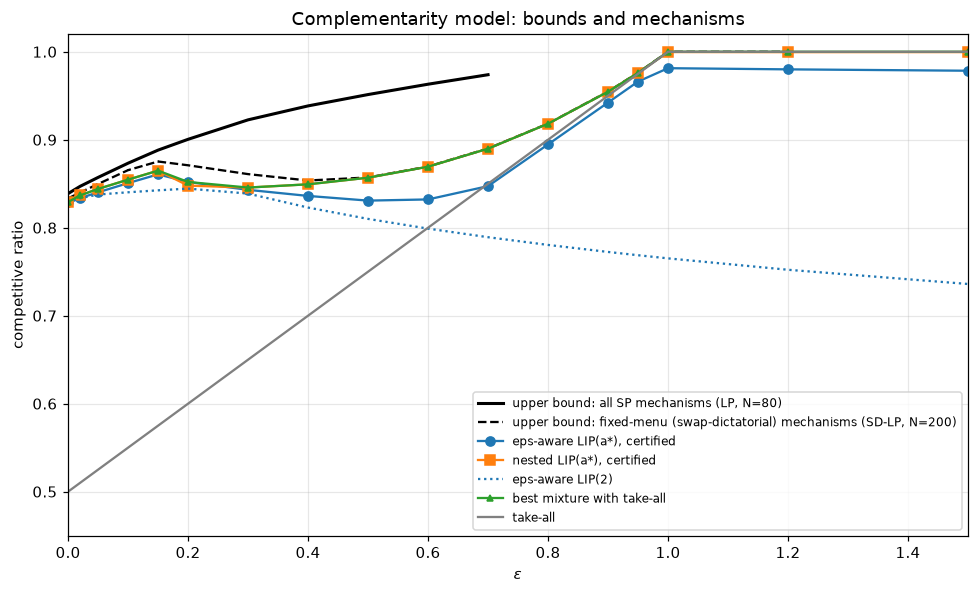

In [5]:
det = pd.read_csv(DATA / "eps_lip_best.csv").sort_values("eps")
nes = pd.read_csv(DATA / "eps_lip_best_nested.csv").sort_values("eps")
lpc = pd.read_csv(DATA / "lp_eps_curve.csv")
sd = pd.read_csv(DATA / "sd_lp_curve.csv").sort_values("eps")
Nmax = lpc.N.max(); lpN = lpc[lpc.N == Nmax].sort_values("eps")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(lpN.eps, lpN.alpha, "k-", lw=2, label=f"upper bound: all SP mechanisms (LP, N={Nmax})")
ax.plot(sd.eps, sd.alpha_sd, "k--", lw=1.5, label=f"upper bound: fixed-menu (swap-dictatorial) mechanisms (SD-LP, N={sd.N.max()})")
ax.plot(det.eps, det.lower, "o-", label="eps-aware LIP(a*), certified")
ax.plot(nes.eps, nes.lower, "s-", label="nested LIP(a*), certified")
ax.plot(det.eps, det.lip2_grid, ":", c="C0", label="eps-aware LIP(2)")
ax.plot(det.eps, np.maximum(det.mix_lower, nes.mix_lower.values if len(nes) == len(det) else det.mix_lower), "^-", ms=4, label="best mixture with take-all")
ax.plot(det.eps, det.takeall, "-", c="gray", label="take-all")
ax.set(xlabel=r"$\varepsilon$", ylabel="competitive ratio", xlim=(0, 1.5), ylim=(0.45, 1.02), title="Complementarity model: bounds and mechanisms")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.savefig(FIG / "03_eps_overview.png"); plt.show()

In [6]:
tab = det[["eps", "a_star", "lower", "upper", "x", "y", "lip2_grid", "lam_star", "mix_lower", "takeall"]].rename(columns={"lower": "LIP(a*) lower", "upper": "LIP(a*) upper", "x": "x_worst", "y": "y_worst"})
tab = tab.merge(nes[["eps", "a_star", "lower"]].rename(columns={"a_star": "a*_nested", "lower": "nested LIP lower"}), on="eps", how="left")
tab = tab.merge(lpN[["eps", "alpha"]].rename(columns={"alpha": "SP upper (LP)"}), on="eps", how="left")
tab = tab.merge(sd[["eps", "alpha_sd"]].rename(columns={"alpha_sd": "SD upper (LP)"}), on="eps", how="left")
tab.round(4)

,eps,a_star,LIP(a*) lower,LIP(a*) upper,x_worst,y_worst,lip2_grid,lam_star,mix_lower,takeall,a*_nested,nested LIP lower,SP upper (LP),SD upper (LP)
0,0.00,2.1011,0.8292,0.8294,0.4175,0.000,0.8281,1.0,0.8292,0.500,2.1014,0.8292,0.8388,0.8333
1,0.00,2.1011,0.8292,0.8294,0.4175,0.000,0.8281,1.0,0.8292,0.500,2.1014,0.8292,0.8388,0.8333
2,0.02,2.0393,0.8337,0.8339,0.4225,0.000,0.8334,1.0,0.8337,0.510,1.9596,0.8368,0.8470,0.8400
3,0.02,2.0393,0.8337,0.8339,0.4225,0.000,0.8334,1.0,0.8337,0.510,1.9596,0.8368,0.8470,0.8400
4,0.05,1.9507,0.8402,0.8404,0.4275,0.000,0.8377,1.0,0.8402,0.525,1.6860,0.8441,0.8572,0.8497
5,0.05,1.9507,0.8402,0.8404,0.4275,0.000,0.8377,1.0,0.8402,0.525,1.6860,0.8441,0.8572,0.8497
6,0.10,1.8129,0.8507,0.8509,1.0000,0.560,0.8403,1.0,0.8507,0.550,1.3826,0.8547,0.8734,0.8654
7,0.10,1.8129,0.8507,0.8509,1.0000,0.560,0.8403,1.0,0.8507,0.550,1.3826,0.8547,0.8734,0.8654
8,0.15,1.6864,0.8606,0.8608,0.4500,0.000,0.8425,1.0,0.8606,0.575,1.2812,0.8649,0.8882,0.8753
9,0.15,1.6864,0.8606,0.8608,0.4500,0.000,0.8425,1.0,0.8606,0.575,1.2812,0.8649,0.8882,0.8753


**Reading the figure.**

* The LP upper bound rises quickly with $\varepsilon$ (complementarity makes pooling attractive,
  and pooling is easy to implement truthfully), reaching 1 at $\varepsilon=1$.
* The best deterministic $\varepsilon$-aware LIP first *improves* (its optimal $a$ falls from
  2.10 to about 1.3), then falls behind because it cannot pool. Nested LIP takes over for
  larger $\varepsilon$ and is first best for $\varepsilon\ge1$.
* The fixed-menu upper bound (dashed) is far below the SP bound for intermediate $\varepsilon$:
  a menu mechanism cannot both pool when agents agree and split when they disagree. The LIP
  variants are close to the *dictatorial* optimum; the large remaining gap is the **price of
  dictatorship** (notebook 04).
* The mixture with take-all helps only marginally.

## 5. Where the worst cases are

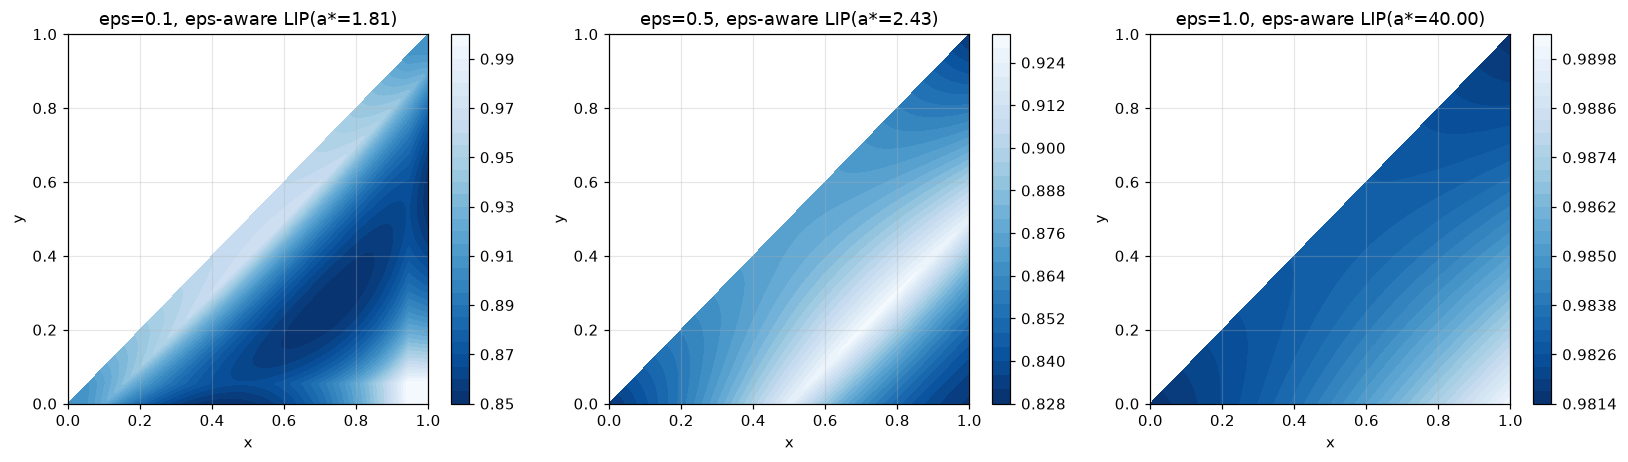

In [7]:
g = np.linspace(0, 1, 301)
X, Y = np.meshgrid(g, g, indexing="ij")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for k, e in enumerate((0.1, 0.5, 1.0)):
    a_star = float(det.loc[(det.eps - e).abs().idxmin(), "a_star"])
    R = np.where(X >= Y, E.ratio_lip(X, Y, a_star, e), np.nan)
    im = ax[k].contourf(X, Y, R, levels=30, cmap="Blues_r"); plt.colorbar(im, ax=ax[k])
    ax[k].set(title=f"eps={e}, eps-aware LIP(a*={a_star:.2f})", xlabel="x", ylabel="y")
plt.tight_layout(); plt.savefig(FIG / "03_worst_cases.png"); plt.show()

At small $\varepsilon$ the picture is the additive one (edge and anti-diagonal). As $\varepsilon$
grows, the worst case moves to the *diagonal* $x=y$ (identical types) where the first best pools
and a dictatorial split cannot — the opposite of the additive model, where identical types were
the easy case (ratio 1).

## Summary

1. LIP survives complementarities as a strategy-proof mechanism (fixed menu), with certified
   ratios; strategic play against the naive rule is outcome-equivalent.
2. Nested lotteries are a free improvement for pooling and make LIP first best for $\varepsilon\ge1$.
3. The LP bound shows much better mechanisms exist for $0<\varepsilon<1$, but not within the
   fixed-menu class: see notebook 04.